In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

RANDOM_STATE = 42
COLOURS = ["tab:blue", "tab:orange", "tab:green", "tab:red", "tab:purple", "tab:brown"]

In [2]:
df = pd.DataFrame({
    "Customer": [f"C{i}" for i in range(1, 13)],
    "Annual_Income": [1.0, 1.5, 2.0, 2.0, 7.0, 7.5, 8.0, 8.0, 4.0, 4.5, 5.0, 5.0],
    "Spending_Score": [1.0, 2.0, 1.5, 2.5, 1.0, 2.0, 1.5, 2.5, 7.0, 8.0, 7.5, 8.5],
})
X = df[["Annual_Income", "Spending_Score"]].values
df

,Customer,Annual_Income,Spending_Score
0,C1,1.0,1.0
1,C2,1.5,2.0
2,C3,2.0,1.5
3,C4,2.0,2.5
4,C5,7.0,1.0
5,C6,7.5,2.0
6,C7,8.0,1.5
7,C8,8.0,2.5
8,C9,4.0,7.0
9,C10,4.5,8.0


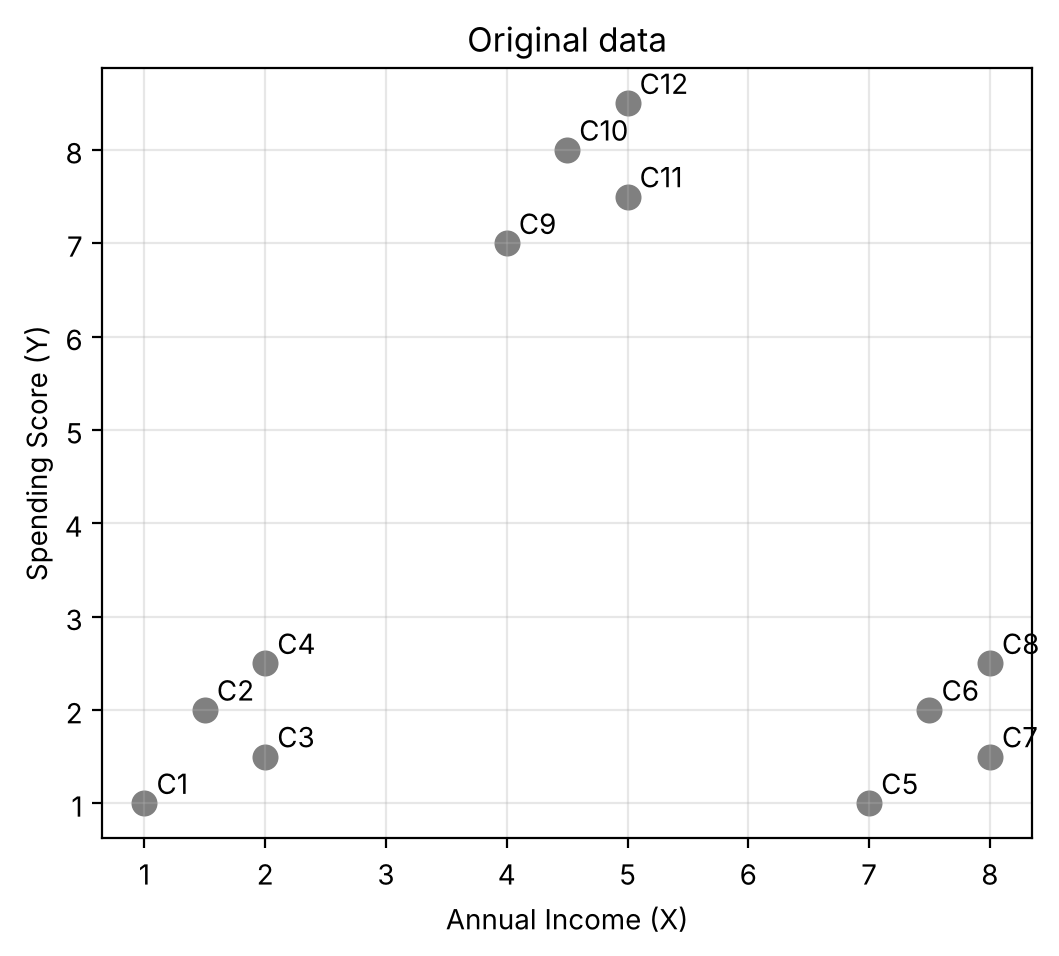

In [3]:
def label_points(ax):
    for _, row in df.iterrows():
        ax.annotate(row["Customer"], (row["Annual_Income"] + 0.1, row["Spending_Score"] + 0.1))

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(df["Annual_Income"], df["Spending_Score"], c="grey", s=70)
label_points(ax)
ax.set_xlabel("Annual Income (X)")
ax.set_ylabel("Spending Score (Y)")
ax.set_title("Original data")
ax.grid(alpha=0.3)
plt.show()

In [4]:
kmeans = KMeans(n_clusters=3, random_state=RANDOM_STATE, n_init=10)
kmeans.fit(X)
centroids = kmeans.cluster_centers_
df["Cluster"] = kmeans.labels_ + 1
print(df[["Customer", "Annual_Income", "Spending_Score", "Cluster"]].to_string(index=False))
print()
for k, cen in enumerate(centroids, start=1):
    print(f"Cluster {k} centroid: ({cen[0]:.3f}, {cen[1]:.3f})")
print(f"Inertia (WCSS): {kmeans.inertia_:.4f}")

Customer  Annual_Income  Spending_Score  Cluster
      C1            1.0             1.0        3
      C2            1.5             2.0        3
      C3            2.0             1.5        3
      C4            2.0             2.5        3
      C5            7.0             1.0        1
      C6            7.5             2.0        1
      C7            8.0             1.5        1
      C8            8.0             2.5        1
      C9            4.0             7.0        2
     C10            4.5             8.0        2
     C11            5.0             7.5        2
     C12            5.0             8.5        2

Cluster 1 centroid: (7.625, 1.750)
Cluster 2 centroid: (4.625, 7.750)
Cluster 3 centroid: (1.625, 1.750)
Inertia (WCSS): 5.8125


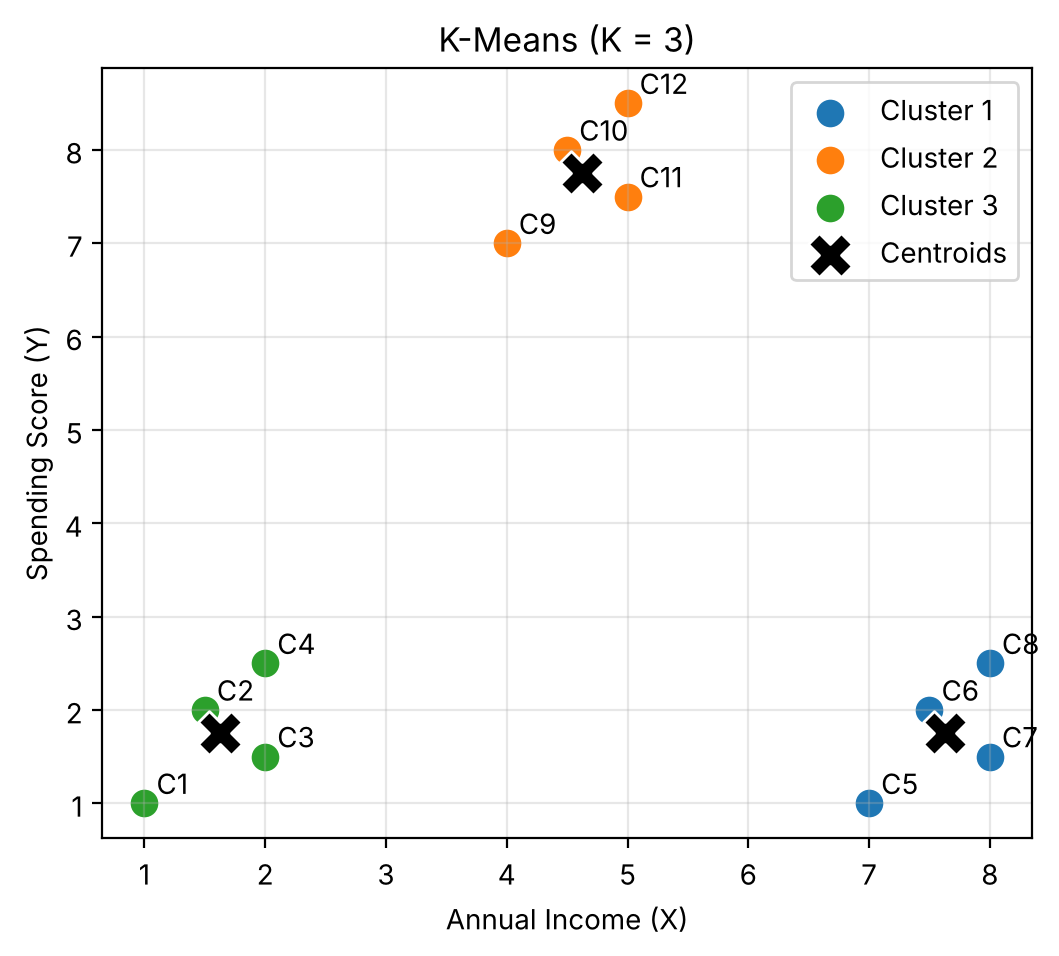

In [5]:
def plot_clusters(labels, centers, title):
    fig, ax = plt.subplots(figsize=(6, 5))
    for k in range(len(centers)):
        mask = labels == k
        ax.scatter(X[mask, 0], X[mask, 1], c=COLOURS[k], s=80, label=f"Cluster {k + 1}")
    ax.scatter(centers[:, 0], centers[:, 1], c="black", marker="X", s=250, edgecolors="white", label="Centroids")
    label_points(ax)
    ax.set_xlabel("Annual Income (X)")
    ax.set_ylabel("Spending Score (Y)")
    ax.set_title(title)
    ax.legend()
    ax.grid(alpha=0.3)
    plt.show()

plot_clusters(kmeans.labels_, centroids, "K-Means (K = 3)")

In [6]:
manual_groups = ["A"] * 4 + ["B"] * 4 + ["C"] * 4
manual_centroids = np.array([[1.625, 1.75], [7.625, 1.75], [4.625, 7.75]])
manual_order = np.array([{"A": 0, "B": 1, "C": 2}[g] for g in manual_groups])

match = {k: int(np.argmin(((manual_centroids - cen) ** 2).sum(axis=1))) for k, cen in enumerate(centroids)}
python_order = np.array([match[l] for l in kmeans.labels_])

print("Same grouping as manual:", bool((python_order == manual_order).all()))
print("Centroids match manual:", bool(np.allclose(centroids[sorted(match, key=match.get)], manual_centroids)))
print("Manual WCSS: 5.8125 | Python inertia:", round(kmeans.inertia_, 4))

Same grouping as manual: True
Centroids match manual: True
Manual WCSS: 5.8125 | Python inertia: 5.8125


In [7]:
k_values = list(range(1, 7))
wcss = [KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10).fit(X).inertia_ for k in k_values]

elbow_table = pd.DataFrame({"K": k_values, "WCSS": np.round(wcss, 4)})
elbow_table["Drop"] = elbow_table["WCSS"].diff().mul(-1).round(4)
elbow_table["Pct_drop"] = (elbow_table["Drop"] / elbow_table["WCSS"].shift(1) * 100).round(1)
elbow_table

,K,WCSS,Drop,Pct_drop
0,1,173.8125,NaN,NaN
1,2,77.8125,96.0000,55.2
2,3,5.8125,72.0000,92.5
3,4,4.5417,1.2708,21.9
4,5,3.2708,1.2709,28.0
5,6,2.0000,1.2708,38.9


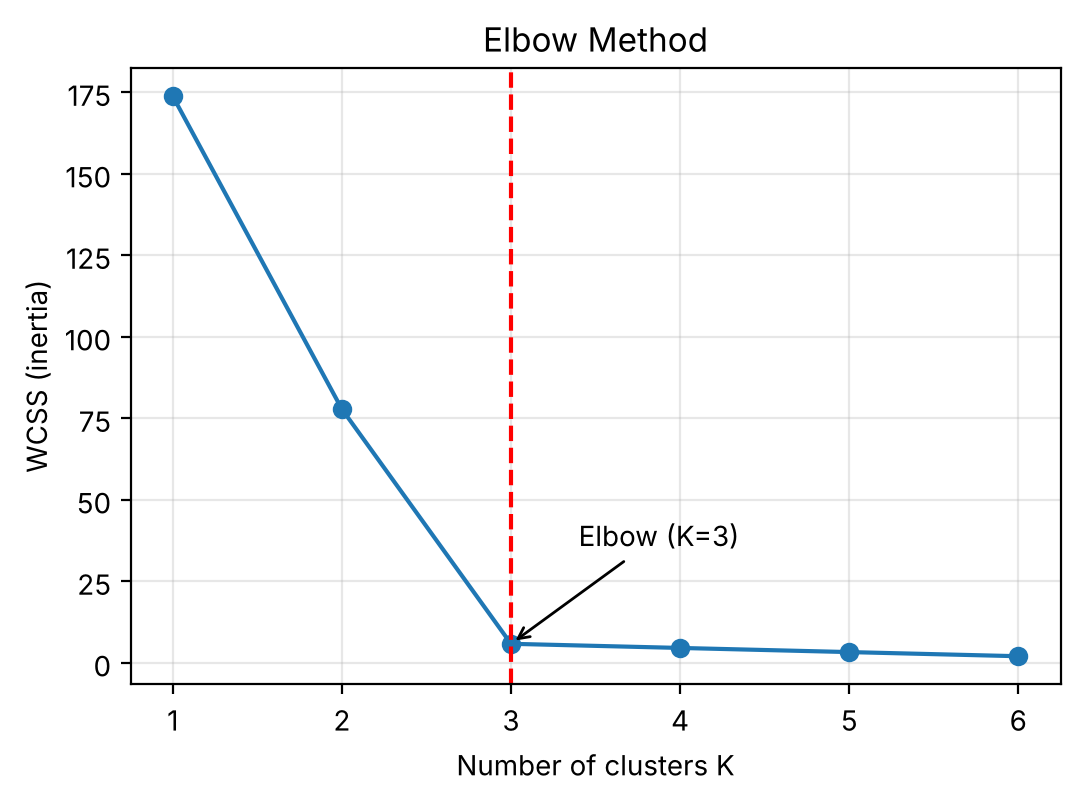

Selected K = 3


In [8]:
drops = -np.diff(wcss)
elbow_k = next(k for k, d in zip(k_values[1:], drops[1:]) if d < 0.05 * drops[0])

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(k_values, wcss, "o-", color="tab:blue")
ax.axvline(elbow_k, ls="--", c="red")
ax.annotate(f"Elbow (K={elbow_k})", (elbow_k, wcss[elbow_k - 1]),
            xytext=(elbow_k + 0.4, wcss[elbow_k - 1] + 30),
            arrowprops=dict(arrowstyle="->"))
ax.set_xlabel("Number of clusters K")
ax.set_ylabel("WCSS (inertia)")
ax.set_title("Elbow Method")
ax.set_xticks(k_values)
ax.grid(alpha=0.3)
plt.show()
print("Selected K =", elbow_k)

Customer  Final_Cluster
      C1              3
      C2              3
      C3              3
      C4              3
      C5              1
      C6              1
      C7              1
      C8              1
      C9              2
     C10              2
     C11              2
     C12              2

[[7.625 1.75 ]
 [4.625 7.75 ]
 [1.625 1.75 ]]


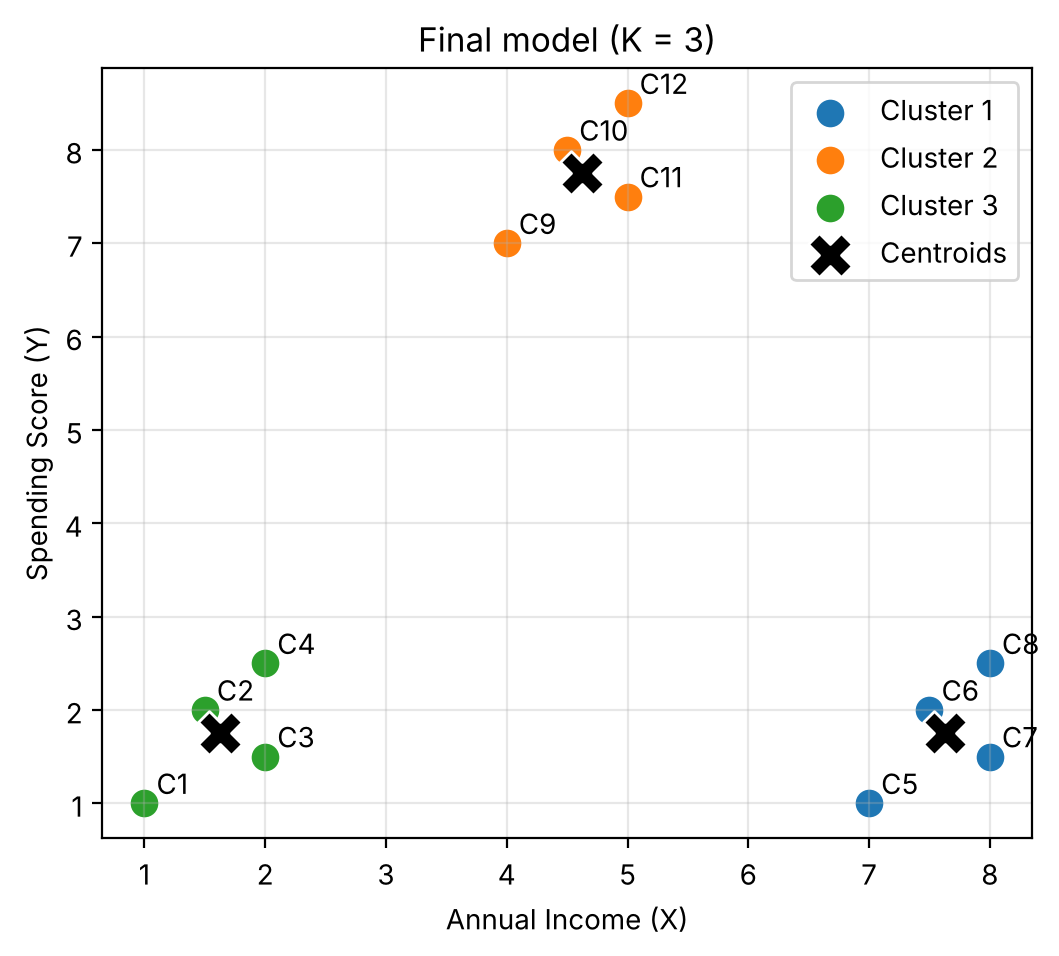

In [9]:
final_model = KMeans(n_clusters=elbow_k, random_state=RANDOM_STATE, n_init=10).fit(X)
df["Final_Cluster"] = final_model.labels_ + 1
print(df[["Customer", "Final_Cluster"]].to_string(index=False))
print()
print(np.round(final_model.cluster_centers_, 3))
plot_clusters(final_model.labels_, final_model.cluster_centers_, f"Final model (K = {elbow_k})")